# 04 · Evaluate and defend

This stage opens July once, using the frozen model. Repeated execution reuses saved results. Do not delete the holdout lock to tune against July.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image
from taxi_tip.config import ROOT, REPORTS, ARTIFACTS
from taxi_tip.data import read_split, clean_trips
print("Project:", ROOT)


Project: C:\Users\mateo\OneDrive\Documents\ChatGPT\ML_project


In [2]:
from taxi_tip.workflow import final_evaluate
result = final_evaluate(repetitions=500)
display(result)
display(pd.read_csv(REPORTS / "test_metrics.csv"))
display(pd.read_csv(REPORTS / "tables" / "bootstrap_intervals.csv"))

July already evaluated; returning saved results without scoring again.


{'completed_utc': '2026-11-03T10:10:04.695964+00:00',
 'n_test': 119811,
 'selected_model': 'tree_depth_8',
 'bootstrap_repetitions': 500,
 'selection_sha256': '768c5f29d1ba006fd5ac0fcf670b4c7250255093e1ee26036ecb48b9ab511c12',
 'predictions_sha256': 'fa13c47ba120a96c1e62daca4257765262e66a69ce2bca6f46ee640301cfb05e',
 'data_sha256': '9f6fadc8308f30f194e9980a170aceadb9e2114e50c1d5d0b574ab82a07c5af0',
 'model_sha256': '94a8feaa3db92f1467a26c5339853337f4cd19e0320ebd717e98ed2c99fd42ce',
 'result': {'model': 'selected',
  'n': 119811,
  'positives': 70035,
  'positive_rate': 0.5845456594135764,
  'average_precision': 0.7474313080285334,
  'precision': 0.7136940146361354,
  'recall': 0.9496965802812879,
  'lift_at_20pct': 1.3278681693412828,
  'brier': 0.18210684852724562,
  'threshold': 0.32,
  'predicted_positive_rate': 0.777841767450401,
  'tp': 66512,
  'fp': 26682,
  'fn': 3523,
  'tn': 23094,
  'cost_per_trip': 0.281510044987522}}

,model,n,positives,positive_rate,average_precision,precision,recall,lift_at_20pct,brier,threshold,predicted_positive_rate,tp,fp,fn,tn,cost_per_trip
0,majority,119811,70035,0.584546,0.584546,0.584546,1.000000,1.000000,0.243375,0.500000,1.000000,70035,49776,0,0,0.415454
1,fare_rule,119811,70035,0.584546,0.656447,0.757259,0.416306,1.295467,0.306788,0.761414,0.321356,29156,9346,40879,40430,0.760398
2,tree_depth_2,119811,70035,0.584546,0.706332,0.644021,0.974156,1.232336,0.199711,0.390000,0.884193,68225,37711,1810,12065,0.344968
3,selected,119811,70035,0.584546,0.747431,0.713694,0.949697,1.327868,0.182107,0.320000,0.777842,66512,26682,3523,23094,0.281510


,metric,estimator,estimate,lower_95,upper_95,repetitions,unit
0,average_precision,model,0.747431,0.743712,0.750789,500,trip
1,average_precision,majority,0.584546,0.581850,0.587326,500,trip
2,average_precision,difference,0.162886,0.160093,0.165725,500,trip
3,precision,model,0.713694,0.710968,0.716392,500,trip
4,precision,majority,0.584546,0.581850,0.587326,500,trip
5,precision,difference,0.129148,0.127540,0.130791,500,trip
6,recall,model,0.949697,0.947941,0.951242,500,trip
7,recall,majority,1.000000,1.000000,1.000000,500,trip
8,recall,difference,-0.050303,-0.052059,-0.048758,500,trip
9,lift_at_20pct,model,1.327868,1.319260,1.336480,500,trip


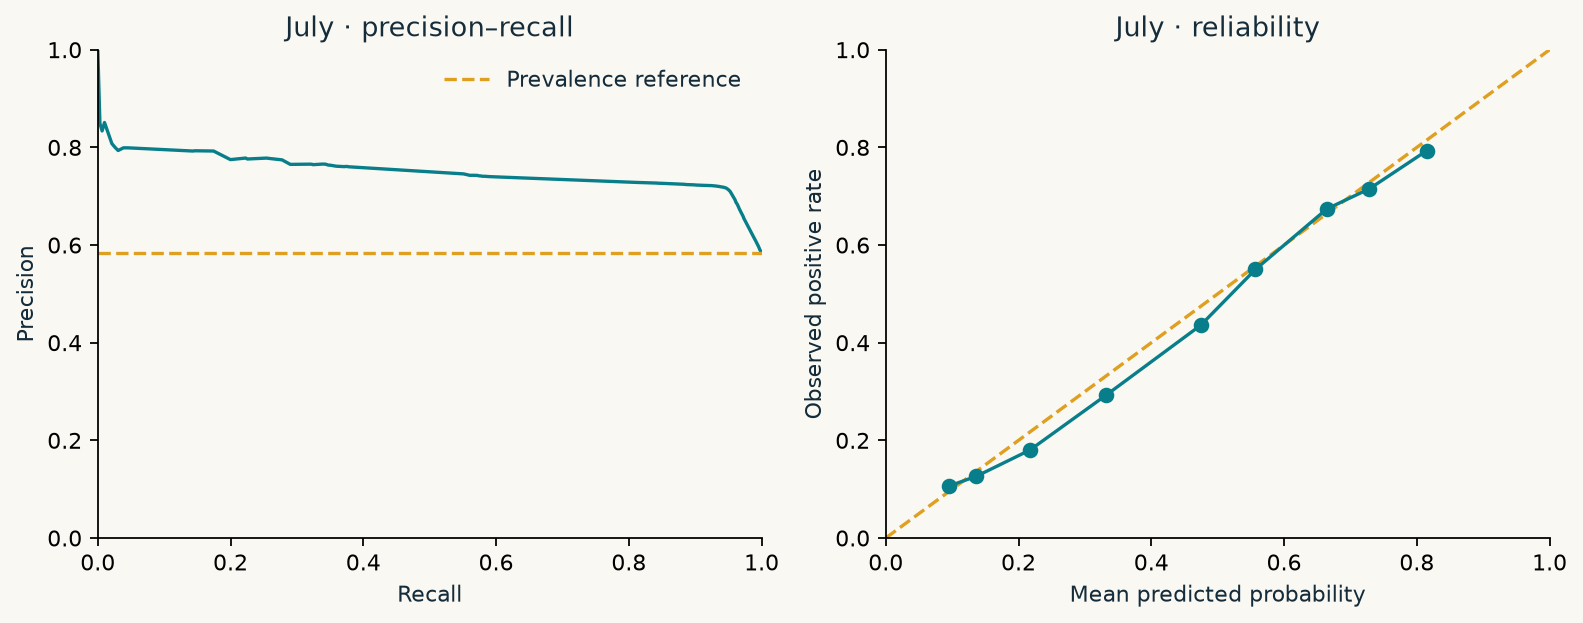

,slice,value,small_sample,n,positives,positive_rate,average_precision,precision,recall,lift_at_20pct,brier,threshold,predicted_positive_rate,tp,fp,fn,tn,cost_per_trip
19,pickup_hour,4,False,553,264,0.477396,0.682886,0.606965,0.924242,1.488724,0.208491,0.32,0.726944,244,158,20,131,0.358047
65,nonstandard_rate,1,False,8424,789,0.093661,0.087552,0.067409,0.153359,0.563410,0.176090,0.32,0.213082,121,1674,668,5961,0.357312
18,pickup_hour,3,False,802,412,0.513716,0.659457,0.617323,0.951456,1.378339,0.215043,0.32,0.791771,392,243,20,147,0.352868
21,pickup_hour,6,False,1549,770,0.497095,0.657482,0.613887,0.941558,1.346736,0.213533,0.32,0.762427,725,456,45,323,0.352485
54,passenger_count,NaN,False,403,235,0.583127,0.732982,0.666667,0.936170,1.305035,0.207724,0.32,0.818859,220,110,15,58,0.347395
20,pickup_hour,5,False,637,305,0.478807,0.631269,0.618736,0.931148,1.439124,0.209630,0.32,0.720565,284,175,21,157,0.340659
56,pickup_borough,Brooklyn,False,699,160,0.228898,0.492496,0.448529,0.762500,2.527634,0.155550,0.32,0.389127,122,150,38,389,0.323319
17,pickup_hour,2,False,1216,678,0.557566,0.682838,0.661570,0.957227,1.229674,0.204941,0.32,0.806743,649,332,29,206,0.320724
4,fare_band,80+,False,1200,187,0.155833,0.211481,0.208333,0.026738,1.477355,0.129497,0.32,0.020000,5,19,182,994,0.319167
22,pickup_hour,7,False,2938,1607,0.546971,0.689834,0.662484,0.952707,1.285567,0.200405,0.32,0.786590,1531,780,76,551,0.317223


,bin,n,predicted,observed
0,"(-0.001, 0.1]",3109,0.095083,0.106465
1,"(0.1, 0.2]",19856,0.136270,0.126259
2,"(0.2, 0.3]",3325,0.217169,0.180150
3,"(0.3, 0.4]",924,0.331545,0.292208
4,"(0.4, 0.5]",576,0.474426,0.435764
5,"(0.5, 0.6]",1442,0.556767,0.549931
6,"(0.6, 0.7]",12467,0.664364,0.673939
7,"(0.7, 0.8]",65147,0.728628,0.715305
8,"(0.8, 0.9]",12965,0.814681,0.793058


In [3]:
display(Image(filename=str(REPORTS / "figures" / "july-performance.png")))
slices = pd.read_csv(REPORTS / "tables" / "test_slices.csv")
display(slices.loc[slices.n >= 200].sort_values("cost_per_trip", ascending=False).head(12))
display(pd.read_csv(REPORTS / "tables" / "test_reliability.csv"))

In [4]:
from taxi_tip.reporting import build_docs
build_docs()
display(Markdown((ROOT / "MODEL_CARD.md").read_text(encoding="utf-8")))

Generated MkDocs pages, model card and defense outline from saved aggregates.


# Model card · generous card-tip baseline

## Intended use and exclusions

An educational, retrospective driver-support study of NYC yellow-taxi trips at payment time. Positive means a recorded card tip at least 25% of positive meter fare. This model is not validated for decisions about service access, routing, pricing, worker evaluation or individual passenger treatment. There is no deployment recommendation.

Cash, flex, no-charge, disputed, unknown-payment and voided trips are outside the population. All findings are conditional on our fixed cleaning rules and observed card trips; neither zeros in cash records nor missing tips establish human generosity.

## Data, fitting and provenance

Instructor data-v2 fixed sample, May–July 2026. Eligible rows: May **129,956**, June **123,162**, July **119,811**. Pickup month defines the split. The selected estimator is **tree_depth_8**, fitted on May only with groups **fare, geography, fees**. Model and threshold choices use June; no refit combines May and June.

Trip file SHA-256: `9f6fadc8308f30f194e9980a170aceadb9e2114e50c1d5d0b574ab82a07c5af0`.

Model SHA-256: `94a8feaa3db92f1467a26c5339853337f4cd19e0320ebd717e98ed2c99fd42ce`.

The source fingerprint, Python/scikit-learn versions, seed and complete decision record are in `reports/selection.json`. July's result and prediction fingerprints are in `reports/final.json`. Row-level data and models remain local and are not in the website.

## Measured performance

| model        |      n |   average_precision |   precision |   recall |   lift_at_20pct |   cost_per_trip |   threshold |
|:-------------|-------:|--------------------:|------------:|---------:|----------------:|----------------:|------------:|
| majority     | 119811 |              0.5845 |      0.5845 |   1.0000 |          1.0000 |          0.4155 |      0.5000 |
| fare_rule    | 119811 |              0.6564 |      0.7573 |   0.4163 |          1.2955 |          0.7604 |      0.7614 |
| tree_depth_2 | 119811 |              0.7063 |      0.6440 |   0.9742 |          1.2323 |          0.3450 |      0.3900 |
| selected     | 119811 |              0.7474 |      0.7137 |   0.9497 |          1.3279 |          0.2815 |      0.3200 |

July AP: **0.7474**, 95% trip-bootstrap interval **[0.7437, 0.7508]**; constant-score baseline AP **0.5845**. AP lift over baseline is **+0.1629**. July top-20% lift is **1.328**. July Brier score is **0.1821**. These results measure the tested model family, not the theoretical ceiling of tipping prediction.

At threshold **0.32**, precision is **71.4%**, recall **95.0%**, and **77.8%** of eligible trips are flagged. False-positive cost is 1 and false-negative cost is 2 hypothetical units; the assumption needs stakeholder validation. July cost is **0.2815** versus **0.4155** for majority.

## Where it fails and why caution is necessary

| slice            | value    |    n |   precision |   recall |   cost_per_trip |
|:-----------------|:---------|-----:|------------:|---------:|----------------:|
| pickup_hour      | 4        |  553 |      0.6070 |   0.9242 |          0.3580 |
| nonstandard_rate | 1        | 8424 |      0.0674 |   0.1534 |          0.3573 |
| pickup_hour      | 3        |  802 |      0.6173 |   0.9515 |          0.3529 |
| pickup_hour      | 6        | 1549 |      0.6139 |   0.9416 |          0.3525 |
| passenger_count  | nan      |  403 |      0.6667 |   0.9362 |          0.3474 |
| pickup_hour      | 5        |  637 |      0.6187 |   0.9311 |          0.3407 |
| pickup_borough   | Brooklyn |  699 |      0.4485 |   0.7625 |          0.3233 |
| pickup_hour      | 2        | 1216 |      0.6616 |   0.9572 |          0.3207 |

These overlapping slices are the highest-cost groups with n ≥ 200; the full slice report includes smaller groups. A useful aggregate ranking does not imply useful predictions in every group. Zones, fare and time describe trip context rather than intent, service quality, rider income or satisfaction. None of those missing concepts can be inferred as causal explanations.

There is only one held-out month. Seasonal shifts, future fares, recording changes and different payment interfaces can change performance. June was reused for feature/model/threshold choices, which makes development scores optimistic. Greedy feature selection is order dependent and uses logistic regression for all candidate groups. Rejected groups: **journey, calendar, passengers, rate, quality**.

No post-hoc calibration was fitted. The reliability diagram and Brier score are diagnostics; predicted probabilities should not be treated as guaranteed individual frequencies. The 500-resample paired bootstrap conditions on fixed predictions and treats trips as independent; it omits selection uncertainty and may understate uncertainty for correlated trips. No causal, fairness, economic-impact or full-year validation has been performed.

## Reproduction and governance

Run the README from a fresh clone. A local exclusive July lock prevents accidental repeat tuning; cached predictions support report recovery. This guard can be bypassed by manual file deletion, so research discipline and the recorded provenance remain necessary. Independent reruns of the same fixed method are replication, not fresh tests.

AI assistance is declared in the README. Team members must understand and verify the work. Peer review and classroom defense remain pending human activities. Future changes must be evaluated on a new, genuinely unseen period; do not optimize against this July result.


## Final defense

Read the model card's limitations, including cash exclusion, hypothetical costs, temporal drift, missing rider context, and trip-level bootstrap assumptions. Review `presentation/DEFEND.md`. Team D reviews Team A: `PEER_REVIEW.md` remains pending until a real repository is reviewed and the review is delivered. AI assistance is disclosed in the README; every team member must understand the implementation.